# 09 Select a config from the Pareto frontier (list of regions)

Runs for every region in `REGIONS` (environment variable, comma separated; default all seven; or edit the list below). For each region it loads the study trials, finds the Pareto frontier of mean macro-F1 against model complexity, applies the three selection strategies and draws the comparison plot. It also writes `{REGION}_selection_summary.csv` and, at the end, one `all_regions_selection_summary.csv`.

Note: these strategies work on the search scores from fold 0. 

In [1]:
from pathlib import Path
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data_dir = Path("data/optuna_regional_gee_configs")
artifact_dir = Path("data/feature_selection_artifacts")

# regions: REGIONS env var (comma separated), default all seven; or set the list here, e.g. ['HIM', 'PEN']
REGIONS = os.environ.get("REGIONS", "HIM,PEN,DES,IGP,WGR,ICR,NEI").split(",")
F1_TOLERANCE = 0.010   # Strategy A: allowed F1 drop from the peak

In [2]:
def load_region(TARGET_REGION):
    """Load the COMPLETE trials of one region and mark the Pareto frontier (maximize F1, minimize complexity)."""
    trials_json_path = data_dir / f"{TARGET_REGION}_all_trials.json"
    assert trials_json_path.exists(), f"File not found: {trials_json_path}"

    with open(trials_json_path, "r") as f:
        trials_raw = json.load(f)

    # Process the flat Optuna JSON format into the expected DataFrame structure
    processed_trials = []
    for t in trials_raw:
        if t.get("state") != "COMPLETE":
            continue
        processed_trials.append({
            "trial_number": int(t["number"]),
            "macro_f1": float(t["values_0"]),
            "model_complexity": float(t["values_1"]),
            "samples_per_year": int(t.get("user_attrs_samples_per_year", 0)),
            "num_input_features": int(t.get("user_attrs_num_features", 0)),
            "numberOfTrees": int(t.get("params_numberOfTrees", 0)),
            "minLeafPopulation": int(t.get("params_minLeafPopulation", 0)),
            "train_fraction": float(t.get("params_train_fraction", 0.0)),
            "feature_strategy": str(t.get("params_feature_strategy", "")),
            "sampling_strategy": str(t.get("params_sampling_strategy", "")),
            "f1_min_year": float(t.get("user_attrs_f1_min_year", float("nan"))),
            "f1_sd_years": float(t.get("user_attrs_f1_sd_years", float("nan")))
        })

    df_all = pd.DataFrame(processed_trials)

    # Dynamically compute the Pareto frontier (Maximize F1, Minimize Complexity)
    is_pareto = []
    for i, row in df_all.iterrows():
        f1 = row["macro_f1"]
        comp = row["model_complexity"]
        dominated = False
        for j, other in df_all.iterrows():
            if i == j: continue
            # A trial is dominated if another trial is equal or better on all axes, and strictly better on at least one
            if (other["macro_f1"] >= f1) and (other["model_complexity"] <= comp) and \
               ((other["macro_f1"] > f1) or (other["model_complexity"] < comp)):
                dominated = True
                break
        is_pareto.append(not dominated)

    df_all["is_pareto"] = is_pareto

    # Filter to Pareto-optimal trials and sort by complexity
    df_pareto = df_all[df_all["is_pareto"]].sort_values("model_complexity").copy().reset_index(drop=True)

    print(f"Loaded {len(df_all)} COMPLETE trials for Region '{TARGET_REGION}'.")
    print(f"Found {len(df_pareto)} non-dominated Pareto frontier candidates.")

    # Classes with too few polygons are scored but low-confidence (data gap); show them next to the selection
    try:
        import spatial_split as ss
        _sc, _gap = ss.scored_classes(TARGET_REGION)
        print(f"[{TARGET_REGION}] low-confidence classes (< {ss.MIN_POLYS} polygons, data gap): {_gap if _gap else 'none'}")
    except Exception as e:
        print("scored-class info not available:", e)
    return df_all, df_pareto

In [3]:
def show_frontier(df_pareto):
    display_cols = [
        "trial_number", "macro_f1", "f1_min_year", "f1_sd_years", "model_complexity", "samples_per_year",
        "num_input_features", "numberOfTrees", "minLeafPopulation",
        "train_fraction", "feature_strategy", "sampling_strategy"
    ]
    print("=== Pareto Frontier Candidates ===")
    with pd.option_context('display.max_columns', None, 'display.width', 1000):
        print(df_pareto[display_cols].to_string(index=False))

In [4]:
def select_strategies(df_pareto, TARGET_REGION):
    """Apply the three selection strategies to one region's frontier. Returns (trial numbers, summary table)."""
    # Baseline references
    peak_f1 = df_pareto["macro_f1"].max()
    min_comp = df_pareto["model_complexity"].min()
    max_comp = df_pareto["model_complexity"].max()
    min_f1 = df_pareto["macro_f1"].min()

    # ----------------------------------------------------
    # Strategy A: Epsilon-Tolerance (Within F1_TOLERANCE of Peak F1)
    # ----------------------------------------------------
    viable_eps = df_pareto[df_pareto["macro_f1"] >= (peak_f1 - F1_TOLERANCE)]
    trial_strat_a = int(viable_eps.loc[viable_eps["model_complexity"].idxmin()]["trial_number"])

    # ----------------------------------------------------
    # Strategy B: Normalized Utopia Distance
    # ----------------------------------------------------
    f1_penalty = (peak_f1 - df_pareto["macro_f1"]) / (peak_f1 - min_f1)
    comp_penalty = (df_pareto["model_complexity"] - min_comp) / (max_comp - min_comp)

    df_pareto["utopia_dist"] = np.sqrt(f1_penalty**2 + comp_penalty**2)
    trial_strat_b = int(df_pareto.loc[df_pareto["utopia_dist"].idxmin()]["trial_number"])

    # ----------------------------------------------------
    # Strategy C: Marginal Return Ratio vs Baseline
    # ----------------------------------------------------
    log_comp = np.log10(df_pareto["model_complexity"])
    log_base = np.log10(min_comp)
    marginal_gain = (df_pareto["macro_f1"] - min_f1) / (log_comp - log_base).replace(0, np.nan)
    df_pareto["marginal_return"] = marginal_gain.fillna(0.0)
    trial_strat_c = int(df_pareto.loc[df_pareto["marginal_return"].idxmax()]["trial_number"])
    trial_peak = int(df_pareto.loc[df_pareto["macro_f1"].idxmax()]["trial_number"])

    # Comparison Table
    selection_summary = []
    for strat_name, t_num in [
        (f"Strategy A: Min Complexity (F1 drop <= {F1_TOLERANCE:.3f})", trial_strat_a),
        ("Strategy B: Normalized Utopia Distance", trial_strat_b),
        ("Strategy C: Max Marginal Return per Log-Complexity", trial_strat_c),
        ("Baseline: Absolute Peak F1 (Unconstrained)", trial_peak)
    ]:
        t_row = df_pareto[df_pareto["trial_number"] == t_num].iloc[0]
        selection_summary.append({
            "Region": TARGET_REGION,
            "Strategy": strat_name,
            "Trial": int(t_num),
            "Macro-F1": t_row["macro_f1"],
            "Worst-year F1": t_row["f1_min_year"],
            "F1 Delta vs Peak": t_row["macro_f1"] - peak_f1,
            "Complexity": t_row["model_complexity"],
            "Complexity Reduction vs Peak": f"{max_comp / t_row['model_complexity']:.1f}x smaller",
            "Trees": int(t_row["numberOfTrees"]),
            "MinLeaf": int(t_row["minLeafPopulation"]),
            "Features": int(t_row["num_input_features"]),
            "Samples": int(t_row["samples_per_year"])
        })

    df_selection_summary = pd.DataFrame(selection_summary)
    print("\n=== Multi-Criteria Selection Comparison ===")
    with pd.option_context('display.max_columns', None, 'display.width', 1000):
        print(df_selection_summary.to_string(index=False))
    df_selection_summary.to_csv(data_dir / f"{TARGET_REGION}_selection_summary.csv", index=False)
    return dict(a=trial_strat_a, b=trial_strat_b, c=trial_strat_c, peak=trial_peak), df_selection_summary

In [5]:
def plot_selection(df_pareto, picks, TARGET_REGION):
    peak_f1 = df_pareto["macro_f1"].max()
    min_f1 = df_pareto["macro_f1"].min()
    trial_strat_a, trial_strat_b, trial_strat_c = picks["a"], picks["b"], picks["c"]

    plt.figure(figsize=(11, 7))

    # 1. Draw Pareto line
    plt.plot(df_pareto["model_complexity"], df_pareto["macro_f1"], color="slategray", linestyle="--", linewidth=1.8, zorder=1)

    # 2. Scatter all Pareto candidates
    scatter = plt.scatter(
        df_pareto["model_complexity"], df_pareto["macro_f1"], c=df_pareto["num_input_features"],
        cmap="Blues", s=140, edgecolor="black", linewidth=1.2, zorder=2, label="Pareto Candidates"
    )
    cbar = plt.colorbar(scatter)
    cbar.set_label("Number of Features / Bands", fontsize=11)

    # 3. Mark selected strategy points
    marker_styles = {
        f"Strategy A (Trial {trial_strat_a})": (trial_strat_a, "gold", "s", 180),
        f"Strategy B (Trial {trial_strat_b})": (trial_strat_b, "limegreen", "^", 180),
        f"Strategy C (Trial {trial_strat_c})": (trial_strat_c, "darkorange", "D", 160),
        "Absolute Peak F1": (picks["peak"], "crimson", "*", 260)
    }

    for label, (t_num, color, marker, sz) in marker_styles.items():
        row = df_pareto[df_pareto["trial_number"] == t_num].iloc[0]
        plt.scatter(
            row["model_complexity"], row["macro_f1"], color=color, marker=marker,
            s=sz, edgecolor="black", linewidth=1.5, zorder=4, label=label
        )

    # 4. Annotate trial details with compact multi-line formatting
    ss_abbr = {"stratified": "strat", "reference_balanced": "ref_bal"}
    fs_abbr = {"uncorrelated": "uncorr", "all": "topN"}
    for _, row in df_pareto.iterrows():
        s_strat = ss_abbr.get(str(row["sampling_strategy"]).lower(), str(row["sampling_strategy"])[:4])
        f_strat = fs_abbr.get(str(row["feature_strategy"]).lower(), str(row["feature_strategy"])[:6])
        smp_k = f"{row['samples_per_year'] / 1000:.1f}k"   # 40,720 -> 40.7k
        label_text = (
            f"Trial {int(row['trial_number'])}\n"
            f"{smp_k} · {int(row['num_input_features'])}B · {int(row['numberOfTrees'])}T · "
            f"L{int(row['minLeafPopulation'])} · SS={s_strat} · FS={f_strat}"
        )
        plt.annotate(
            label_text,
            xy=(row["model_complexity"], row["macro_f1"]),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=7,
            linespacing=1.1,
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="darkgray", lw=0.7, alpha=0.9)
        )

    plt.xscale("log")
    plt.title(f"Pareto Frontier Multi-Criteria Selection Comparison ({TARGET_REGION})", fontsize=14, pad=15)
    plt.xlabel("Model Complexity (Log Scale: Samples × Bands × Trees × Max Nodes)", fontsize=12)
    plt.ylabel("Mean Annual Macro-F1", fontsize=12)
    plt.grid(True, which="both", linestyle="--", alpha=0.5)

    y_pad = (peak_f1 - min_f1) * 0.25
    plt.ylim(min_f1 - 0.005, peak_f1 + y_pad)
    plt.legend(loc="lower right", frameon=True, fontsize=10)
    plt.tight_layout()

    comparison_plot_path = data_dir / f"{TARGET_REGION}_selection_comparison.png"
    plt.savefig(comparison_plot_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Selection visual saved -> {comparison_plot_path}")


HIM
Loaded 100 COMPLETE trials for Region 'HIM'.
Found 30 non-dominated Pareto frontier candidates.
[HIM] low-confidence classes (< 10 polygons, data gap): [11]
=== Pareto Frontier Candidates ===
 trial_number  macro_f1  f1_min_year  f1_sd_years  model_complexity  samples_per_year  num_input_features  numberOfTrees  minLeafPopulation  train_fraction feature_strategy  sampling_strategy
           76  0.704398     0.625340     0.044150      8.829930e+08              3082                  30             50                 10             0.1     uncorrelated reference_balanced
           39  0.721782     0.584335     0.071228      9.661785e+08              3173                  30             50                  8             0.1     uncorrelated         stratified
           73  0.721782     0.584335     0.071228      9.661785e+08              3173                  30             50                  8             0.1     uncorrelated         stratified
           42  0.721908     0.59217

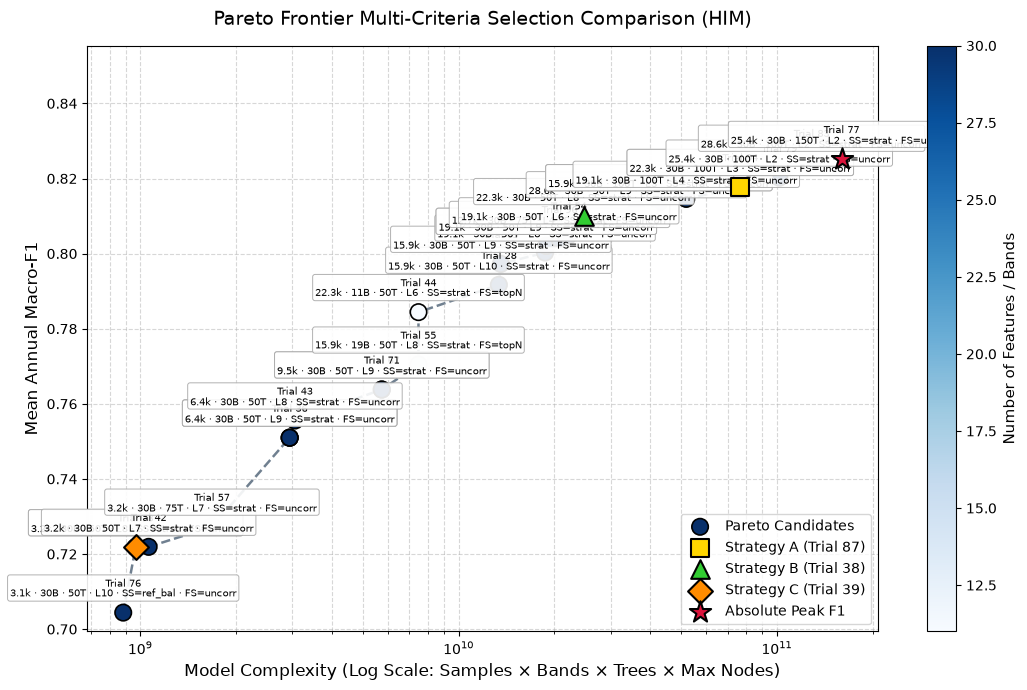

Selection visual saved -> data/optuna_regional_gee_configs/HIM_selection_comparison.png

PEN
Loaded 100 COMPLETE trials for Region 'PEN'.
Found 19 non-dominated Pareto frontier candidates.
[PEN] low-confidence classes (< 10 polygons, data gap): none
=== Pareto Frontier Candidates ===
 trial_number  macro_f1  f1_min_year  f1_sd_years  model_complexity  samples_per_year  num_input_features  numberOfTrees  minLeafPopulation  train_fraction feature_strategy  sampling_strategy
           56  0.560992     0.472842     0.053822      1.410608e+09              3943                  15             50                  5             0.1              all reference_balanced
           29  0.567561     0.476465     0.057902      1.562414e+09              3943                  25             50                  9             0.1              all reference_balanced
           41  0.569928     0.484124     0.058943      1.612687e+09              3943                  20             50                  6

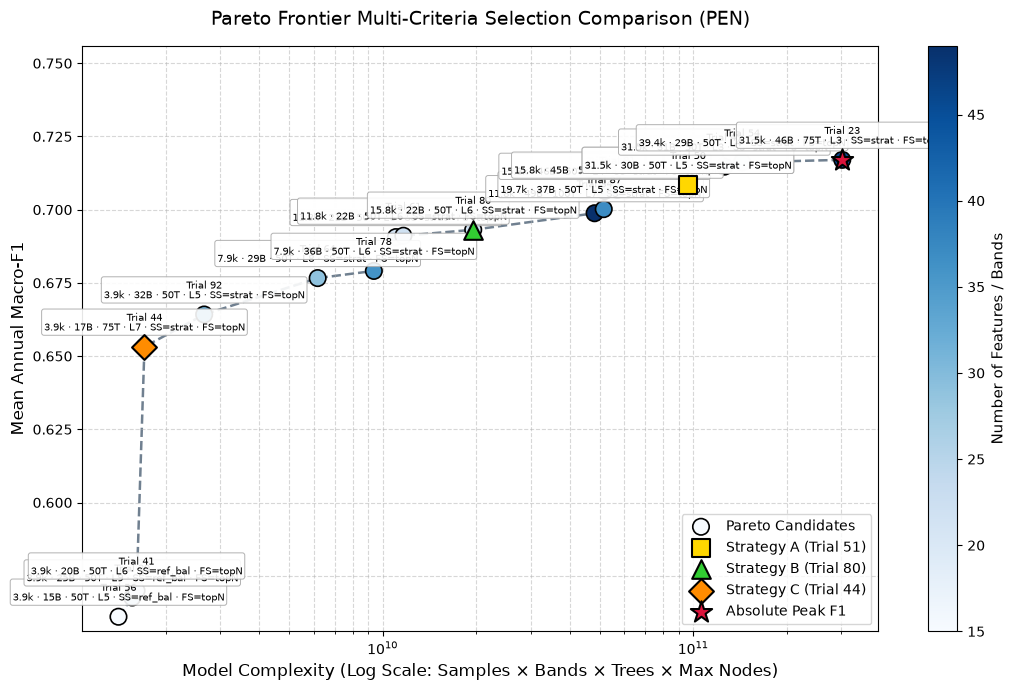

Selection visual saved -> data/optuna_regional_gee_configs/PEN_selection_comparison.png

DES
Loaded 100 COMPLETE trials for Region 'DES'.
Found 14 non-dominated Pareto frontier candidates.
[DES] low-confidence classes (< 10 polygons, data gap): [61]
=== Pareto Frontier Candidates ===
 trial_number  macro_f1  f1_min_year  f1_sd_years  model_complexity  samples_per_year  num_input_features  numberOfTrees  minLeafPopulation  train_fraction feature_strategy sampling_strategy
           50  0.502463     0.415434     0.044184      7.254890e+09              7951                  33             50                  8             0.1     uncorrelated        stratified
           74  0.515520     0.449843     0.046479      7.825374e+09              7951                  14            100                  4             0.1              all        stratified
           63  0.540221     0.474116     0.045546      8.010632e+09              7951                  26             50                  2   

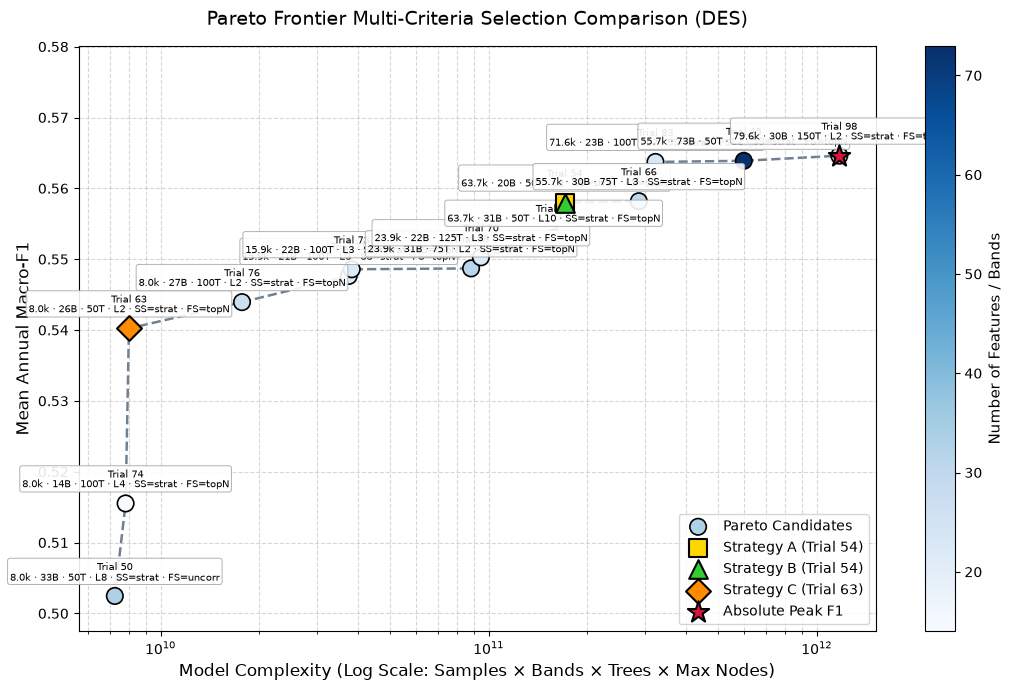

Selection visual saved -> data/optuna_regional_gee_configs/DES_selection_comparison.png

IGP
Loaded 100 COMPLETE trials for Region 'IGP'.
Found 14 non-dominated Pareto frontier candidates.
[IGP] low-confidence classes (< 10 polygons, data gap): none
=== Pareto Frontier Candidates ===
 trial_number  macro_f1  f1_min_year  f1_sd_years  model_complexity  samples_per_year  num_input_features  numberOfTrees  minLeafPopulation  train_fraction feature_strategy  sampling_strategy
           12  0.740700     0.653664     0.052108      5.654136e+09              5594                  65             50                 11             0.1              all reference_balanced
           69  0.742124     0.651411     0.057980      6.240806e+09              5594                  35             75                  8             0.1     uncorrelated reference_balanced
           45  0.752577     0.669149     0.048253      7.484789e+09              5589                  96             50                 12

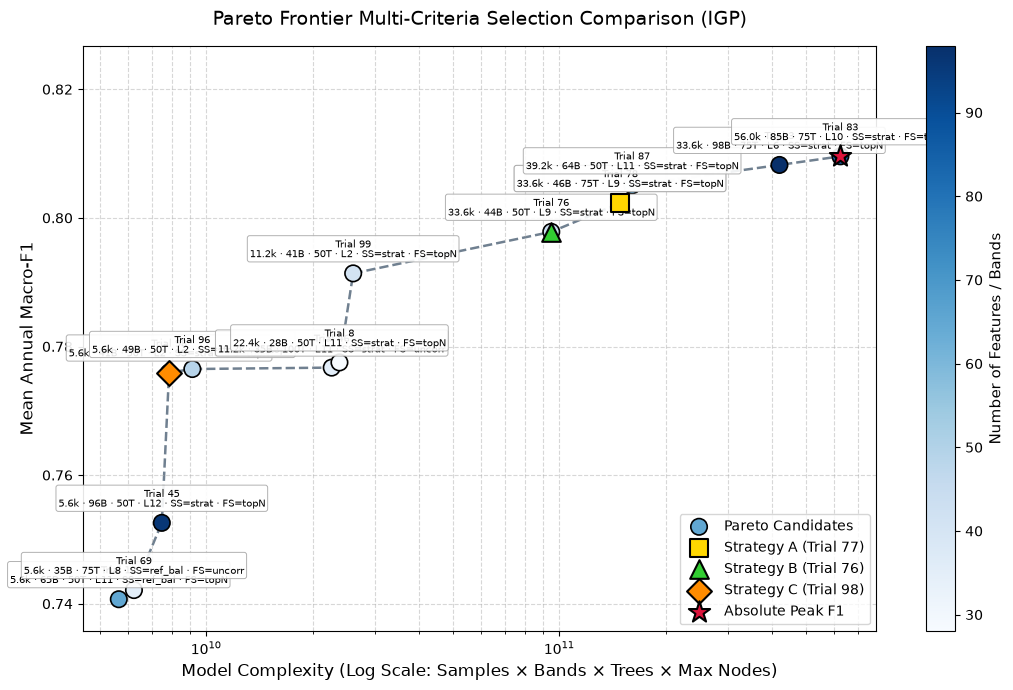

Selection visual saved -> data/optuna_regional_gee_configs/IGP_selection_comparison.png

WGR
Loaded 100 COMPLETE trials for Region 'WGR'.
Found 9 non-dominated Pareto frontier candidates.
[WGR] low-confidence classes (< 10 polygons, data gap): none
=== Pareto Frontier Candidates ===
 trial_number  macro_f1  f1_min_year  f1_sd_years  model_complexity  samples_per_year  num_input_features  numberOfTrees  minLeafPopulation  train_fraction feature_strategy sampling_strategy
           65  0.670126     0.607925     0.037757      1.647775e+09              4149                  13             50                  2             0.1              all        stratified
           74  0.672601     0.605643     0.033354      3.118528e+09              8305                  10             50                  3             0.2              all        stratified
           81  0.674422     0.610877     0.038084      3.295551e+09              4149                  13            100                  2    

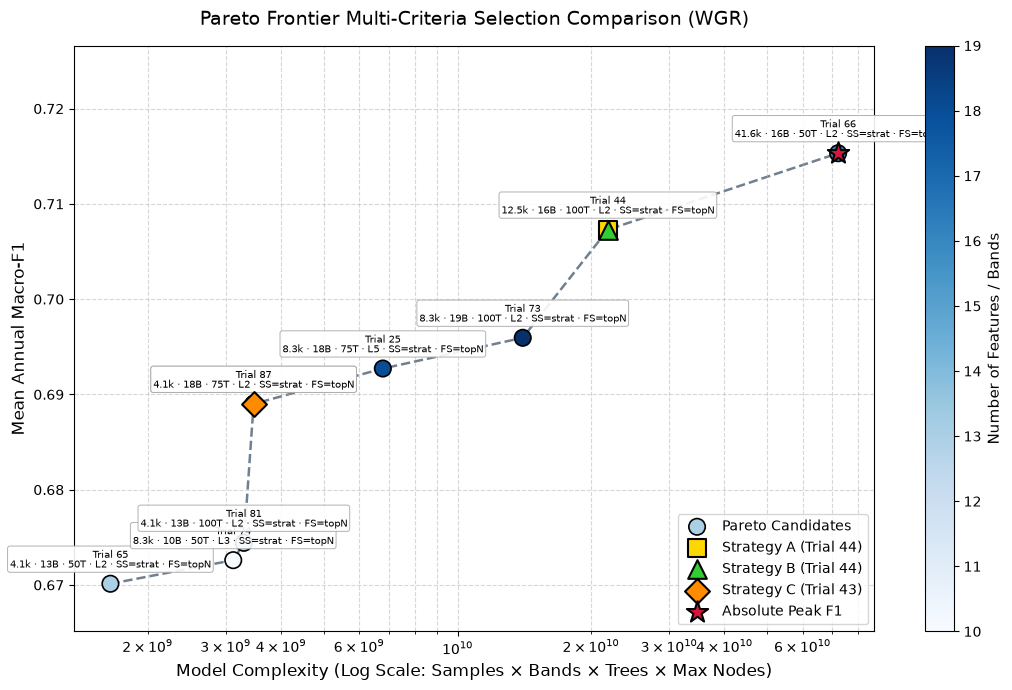

Selection visual saved -> data/optuna_regional_gee_configs/WGR_selection_comparison.png

ICR
Loaded 100 COMPLETE trials for Region 'ICR'.
Found 26 non-dominated Pareto frontier candidates.
[ICR] low-confidence classes (< 10 polygons, data gap): none
=== Pareto Frontier Candidates ===
 trial_number  macro_f1  f1_min_year  f1_sd_years  model_complexity  samples_per_year  num_input_features  numberOfTrees  minLeafPopulation  train_fraction feature_strategy  sampling_strategy
           15  0.597037     0.577396     0.016569      9.545613e+08              5766                  11             50                 12             0.1              all reference_balanced
           31  0.605396     0.545491     0.037637      1.327198e+09              5783                  18             50                 12             0.1              all         stratified
           62  0.628451     0.587985     0.024595      1.544928e+09              5783                  13             50                  5

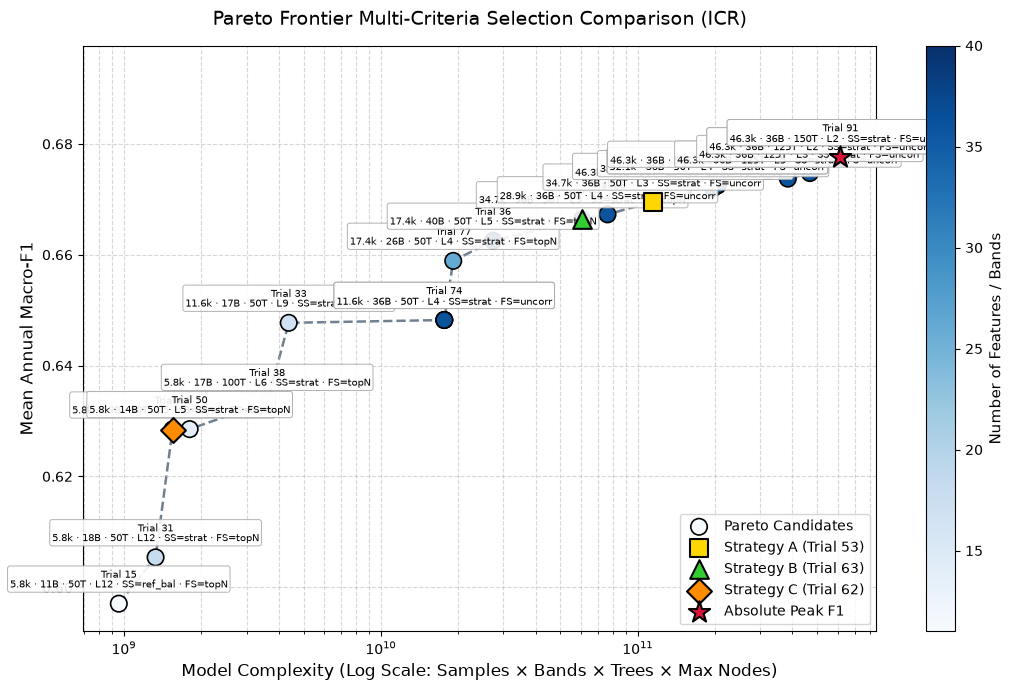

Selection visual saved -> data/optuna_regional_gee_configs/ICR_selection_comparison.png

NEI
Loaded 100 COMPLETE trials for Region 'NEI'.
Found 11 non-dominated Pareto frontier candidates.
[NEI] low-confidence classes (< 10 polygons, data gap): none
=== Pareto Frontier Candidates ===
 trial_number  macro_f1  f1_min_year  f1_sd_years  model_complexity  samples_per_year  num_input_features  numberOfTrees  minLeafPopulation  train_fraction feature_strategy  sampling_strategy
           21  0.631280     0.601367     0.018294      2.348537e+09              9806                  10             50                 12             0.1              all reference_balanced
           15  0.637473     0.600589     0.022879      2.637324e+09              9806                  11             50                 12             0.1              all reference_balanced
           56  0.652878     0.629952     0.013718      3.650500e+09              9800                  10             50                  5

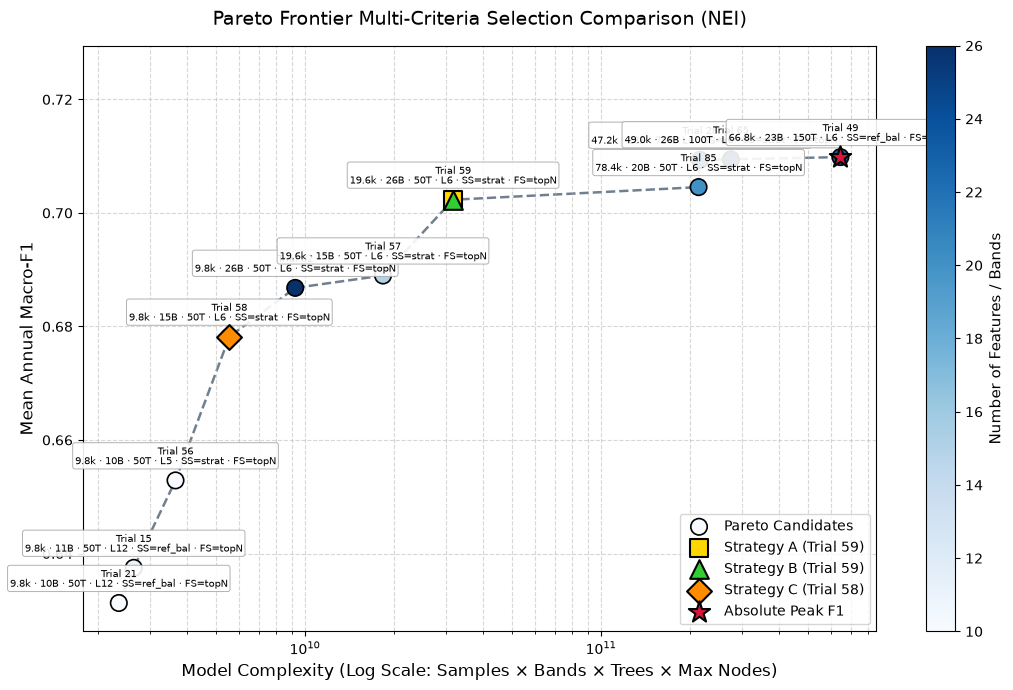

Selection visual saved -> data/optuna_regional_gee_configs/NEI_selection_comparison.png

Combined summary saved -> data/optuna_regional_gee_configs/all_regions_selection_summary.csv


In [6]:
all_summaries = []
for TARGET_REGION in REGIONS:
    print(f"\n{'=' * 70}\n{TARGET_REGION}\n{'=' * 70}")
    try:
        df_all, df_pareto = load_region(TARGET_REGION)
    except AssertionError as e:
        print("skipped:", e)
        continue
    show_frontier(df_pareto)
    picks, summary = select_strategies(df_pareto, TARGET_REGION)
    plot_selection(df_pareto, picks, TARGET_REGION)
    all_summaries.append(summary)

if all_summaries:
    df_all_regions = pd.concat(all_summaries, ignore_index=True)
    df_all_regions.to_csv(data_dir / "all_regions_selection_summary.csv", index=False)
    print(f"\nCombined summary saved -> {data_dir / 'all_regions_selection_summary.csv'}")